---
## Section 0 — Environment Setup & Imports

In [ ]:
!pip install -q -U keras-tuner
!pip install -q tabulate

In [ ]:
%load_ext tensorboard

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow import keras
from keras.callbacks import TensorBoard, EarlyStopping, ReduceLROnPlateau
from keras import Input, Model
from keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense,
                          Dropout, BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.utils import to_categorical
from scipy.stats import entropy as scipy_entropy

from tabulate import tabulate
from PIL import Image
from tqdm import tqdm

import os, gc, json, zipfile, collections, datetime
import keras_tuner as kt
import pandas as pd
import numpy as np
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

import plotly.express as px
from sklearn.preprocessing import LabelEncoder

print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('No GPU — Runtime > Change runtime type > T4 GPU')

TensorFlow: 2.19.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## Section 1 — Dataset Loading & Exploratory Analysis

Five emotion classes: **Angry, Fear, Happy, Sad, Surprise**.  
Images are loaded into RAM, converted to **grayscale** and resized to **96×96** px.  
This resolution matches Exercise 2 (MobileNetV2 minimum), enabling a direct comparison.  
An RGB variant (Dataset D) is built from the same arrays by channel replication — no disk reload needed.

In [ ]:
SEED       = 42
INPUT_SIZE = 96
NUM_COLORS = 1
BATCH_SIZE = 64
EPOCHS     = 80
COLORS     = ['#2E75B6', '#C00000', '#70AD47', '#FFC000', '#9B59B6']

os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

KAGGLE_DATA = '/kaggle/input/human-face-emotions/Data'

if os.path.isdir(KAGGLE_DATA):
    data_dir = KAGGLE_DATA
    print('Kaggle environment detected. Dataset mounted directly.')
else:
    import kagglehub
    path = kagglehub.dataset_download('samithsachidanandan/human-face-emotions')
    print('Dataset path:', path)
    for root, dirs, files_list in os.walk(path):
        level  = root.replace(path, '').count(os.sep)
        indent = ' ' * 2 * level
        print(f'{indent}{os.path.basename(root)}/')
        if level < 2:
            for f in files_list[:3]:
                print(f'{indent}  {f}')
    data_candidate = os.path.join(path, 'Data')
    if os.path.isdir(data_candidate):
        data_dir = data_candidate
    else:
        data_dir = None
        for root, dirs, _ in os.walk(path):
            for d in dirs:
                if d.lower() == 'data':
                    candidate = os.path.join(root, d)
                    if len([s for s in os.listdir(candidate)
                            if os.path.isdir(os.path.join(candidate, s))]) >= 5:
                        data_dir = candidate; break
            if data_dir: break
        if data_dir is None:
            raise FileNotFoundError('Data folder not found.')
    print('Colab environment detected.')

print(f'\nData directory: {data_dir}')

CANONICAL = {'angry':'Angry','fear':'Fear','happy':'Happy',
             'sad':'Sad','surprise':'Surprise','suprise':'Surprise'}
canon_to_folder = {}
for f in sorted(os.listdir(data_dir)):
    if os.path.isdir(os.path.join(data_dir, f)):
        c = CANONICAL.get(f.lower())
        if c and c not in canon_to_folder:
            canon_to_folder[c] = f

CLASS_NAMES  = sorted(canon_to_folder.keys())
FOLDER_NAMES = [canon_to_folder[c] for c in CLASS_NAMES]
NUM_CLASSES  = len(CLASS_NAMES)
class_to_idx = {cls: i for i, cls in enumerate(CLASS_NAMES)}
print(f'Classes: {CLASS_NAMES}')


Kaggle environment detected. Dataset mounted directly.

Data directory: /kaggle/input/human-face-emotions/Data
Classes: ['Angry', 'Fear', 'Happy', 'Sad', 'Surprise']


In [ ]:
SOLID_STD_THRESHOLD = 1.0
detected = []

for cls, folder in zip(CLASS_NAMES, FOLDER_NAMES):
    cls_path = os.path.join(data_dir, folder)
    if not os.path.isdir(cls_path):
        continue
    for fname in sorted(os.listdir(cls_path)):
        if not fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            continue
        fpath = os.path.join(cls_path, fname)
        try:
            arr = np.array(
                Image.open(fpath).convert('L')
                     .resize((32, 32), Image.BILINEAR),
                dtype=np.float32)
            if arr.std() < SOLID_STD_THRESHOLD:
                detected.append({
                    'class':    cls,
                    'filename': fname,
                    'filepath': fpath,
                    'std':      float(arr.std())
                })
        except Exception as e:
            print(f'Read error: {fpath} — {e}')

print(f'Solid colour images detected: {len(detected)}')
if detected:
    print()
    for r in detected:
        print(f"  [{r['class']:10s}] std={r['std']:.4f}  {r['filename']}")
    print()

SOLID_BLACKLIST = {r['filepath'] for r in detected}
print(f'\nBlacklisted: {len(SOLID_BLACKLIST)} images (skipped at load time)')

Solid colour images detected: 22

  [Angry     ] std=0.0000  11286.png
  [Angry     ] std=0.0000  13148.png
  [Angry     ] std=0.0000  13402.png
  [Angry     ] std=0.0000  15878818.png
  [Angry     ] std=0.0000  15894.png
  [Angry     ] std=0.0000  19885833.png
  [Angry     ] std=0.0000  22198.png
  [Angry     ] std=0.0000  2387286.png
  [Angry     ] std=0.0000  26065204.png
  [Angry     ] std=0.0000  28601.png
  [Angry     ] std=0.0000  30002.png
  [Angry     ] std=0.0000  6458.png
  [Angry     ] std=0.0000  65799569.png
  [Angry     ] std=0.0000  66143550.png
  [Angry     ] std=0.0000  75698697.png
  [Angry     ] std=0.0000  94894933.png
  [Happy     ] std=0.0000  7629.png
  [Happy     ] std=0.0000  770748690.png
  [Sad       ] std=0.0000  10423.png
  [Sad       ] std=0.0000  284816882.png
  [Surprise  ] std=0.0000  13988.png
  [Surprise  ] std=0.0000  35589549.png


Blacklisted: 22 images (skipped at load time)


Suspicious images found: 2259


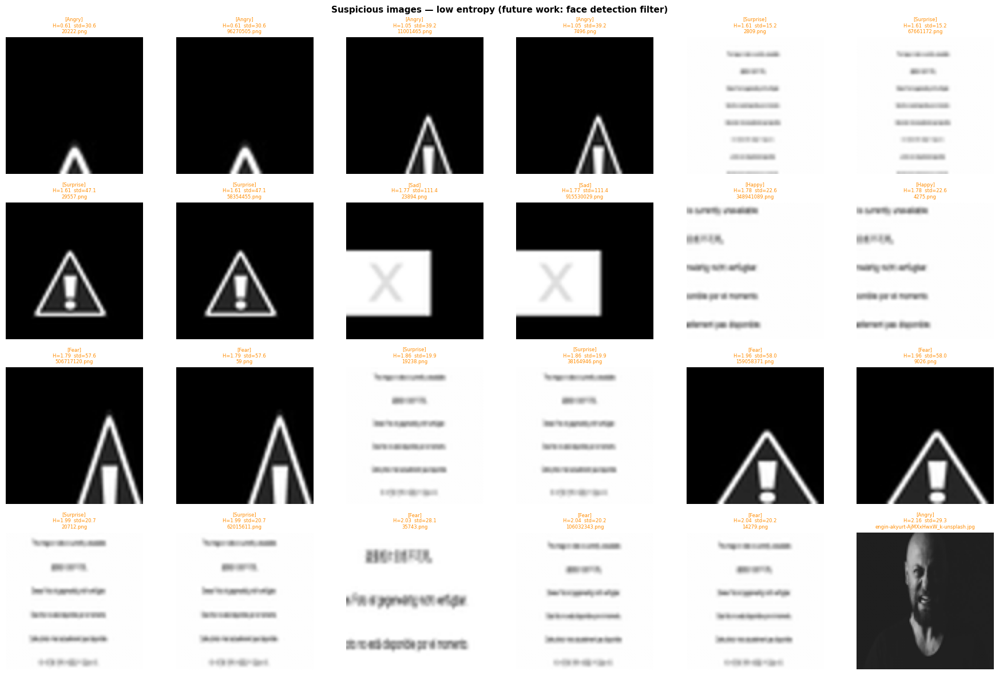


Not deleted automatically. A face detector such as MediaPipe or
OpenCV Haar would be needed to distinguish these from dark faces.


In [ ]:
from scipy.stats import entropy as scipy_entropy

STD_MIN     = 5.0
ENTROPY_MAX = 4.5
N_SHOW      = 24

suspicious = []
for cls, folder in zip(CLASS_NAMES, FOLDER_NAMES):
    cls_path = os.path.join(data_dir, folder)
    if not os.path.isdir(cls_path):
        continue
    for fname in sorted(os.listdir(cls_path)):
        if not fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            continue
        fpath = os.path.join(cls_path, fname)
        try:
            arr  = np.array(
                Image.open(fpath).convert('L')
                     .resize((96, 96), Image.BILINEAR),
                dtype=np.float32)
            std  = arr.std()
            if std < STD_MIN:
                continue
            hist, _ = np.histogram(arr.astype(np.uint8),
                                   bins=256, range=(0, 256), density=True)
            hist = hist[hist > 0]
            ent  = float(scipy_entropy(hist))
            if ent < ENTROPY_MAX:
                suspicious.append({
                    'class':    cls,
                    'filepath': fpath,
                    'filename': fname,
                    'std':      float(std),
                    'entropy':  ent,
                })
        except Exception:
            pass

suspicious.sort(key=lambda r: r['entropy'])
print(f'Suspicious images found: {len(suspicious)}')

if suspicious:
    n     = min(N_SHOW, len(suspicious))
    ncols = 6
    nrows = max(1, (n + ncols - 1) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3))
    axes = axes.flatten()
    for ax, r in zip(axes, suspicious[:n]):
        img = Image.open(r['filepath']).convert('L').resize((96, 96))
        ax.imshow(np.array(img), cmap='gray', vmin=0, vmax=255)
        ax.set_title(
            f"[{r['class']}]\nH={r['entropy']:.2f}  std={r['std']:.1f}\n{r['filename']}",
            fontsize=6, color='darkorange')
        ax.axis('off')
    for ax in axes[n:]:
        ax.axis('off')
    plt.suptitle(
        'Suspicious images — low entropy (future work: face detection filter)',
        fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig('suspicious_images.png', dpi=150, bbox_inches='tight')
    plt.show()
    print()
    print('Not deleted automatically.')
else:
    print('No suspicious images found.')

In [ ]:
total = sum(len(os.listdir(os.path.join(data_dir, f))) for f in FOLDER_NAMES)
print(f'Total images: {total:,}')

X_all          = np.zeros((total, INPUT_SIZE, INPUT_SIZE, NUM_COLORS), dtype=np.float32)
labels_all     = np.zeros(total, dtype=np.int32)
filepaths_all  = []

ptr = 0
for cls, folder in zip(CLASS_NAMES, FOLDER_NAMES):
    cls_path = os.path.join(data_dir, folder)
    cid      = class_to_idx[cls]
    for img_file in tqdm(sorted(os.listdir(cls_path)), desc=f'{cls:10s}', leave=False):
        fpath = os.path.join(cls_path, img_file)
        if fpath in SOLID_BLACKLIST:
            continue
        try:
            img = (Image.open(fpath)
                        .convert('L')
                        .resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR))
            X_all[ptr]         = np.array(img, dtype=np.float32)[..., np.newaxis] / 255.0
            labels_all[ptr]    = cid
            filepaths_all.append(fpath)
            ptr += 1
        except Exception:
            pass

X_all         = X_all[:ptr]
labels_all    = labels_all[:ptr]
filepaths_all = np.array(filepaths_all[:ptr])
y_all         = to_categorical(labels_all, NUM_CLASSES)

print(f'Loaded: {X_all.shape}')
for cls, cid in class_to_idx.items():
    print(f'  {cls:10s}: {np.sum(labels_all == cid):6,} images')


Total images: 59,099


Loaded: (59077, 96, 96, 1)
  Angry     : 10,132 images
  Fear      :  9,732 images
  Happy     : 18,437 images
  Sad       : 12,551 images
  Surprise  :  8,225 images


In [ ]:
print(f'Filepath index ready: {len(filepaths_all):,} entries')


Filepath index ready: 59,077 entries


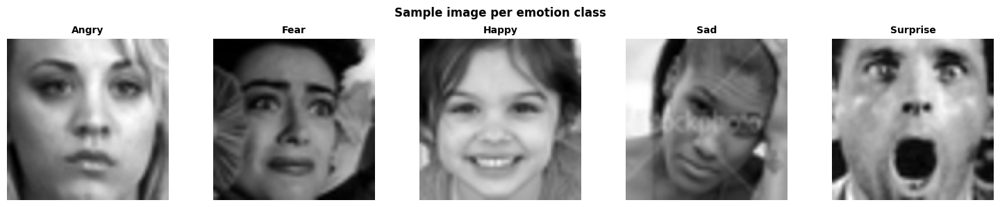

In [ ]:
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 3))
for ax, cls in zip(axes, CLASS_NAMES):
    viz_rng = np.random.default_rng(SEED)
    sample = viz_rng.choice(np.where(labels_all == class_to_idx[cls])[0])
    ax.imshow(X_all[sample].squeeze(), cmap='gray')
    ax.set_title(cls, fontsize=10, fontweight='bold')
    ax.axis('off')
plt.suptitle('Sample image per emotion class', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

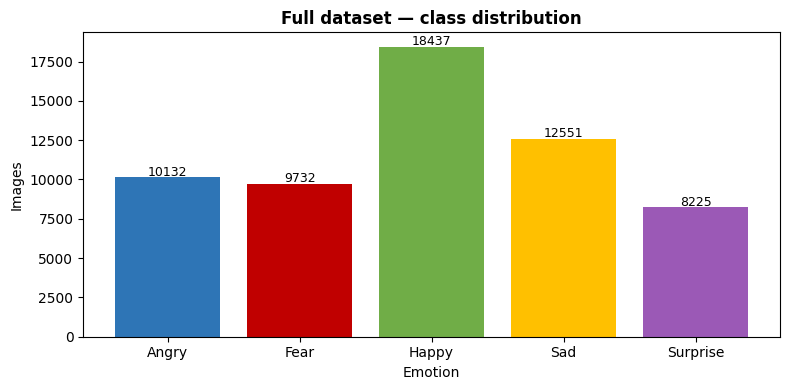

Most frequent : Happy -> 18,437
Least frequent: Surprise -> 8,225
Imbalance ratio: 2.24x


In [ ]:
counts_all = collections.Counter(labels_all)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar([CLASS_NAMES[i] for i in sorted(counts_all)],
              [counts_all[i]   for i in sorted(counts_all)], color=COLORS)
ax.set_title('Full dataset — class distribution', fontweight='bold')
ax.set_ylabel('Images'); ax.set_xlabel('Emotion')
for bar, (k, v) in zip(bars, sorted(counts_all.items())):
    ax.text(bar.get_x() + bar.get_width()/2, v + 120, str(v), ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('class_distribution_full.png', dpi=150, bbox_inches='tight')
plt.show()

min_cid   = min(counts_all, key=counts_all.get)
min_count = counts_all[min_cid]
max_cid   = max(counts_all, key=counts_all.get)
max_count = counts_all[max_cid]
print(f'Most frequent : {CLASS_NAMES[max_cid]} -> {max_count:,}')
print(f'Least frequent: {CLASS_NAMES[min_cid]} -> {min_count:,}')
print(f'Imbalance ratio: {max_count/min_count:.2f}x')

---
## Section 2 — Shared Test Set Extraction

The test set is extracted **before** creating any of the three datasets.  
This guarantees that **all models are evaluated on the exact same images**, making comparisons between Dataset A, B and C fully fair and unbiased.
The remaining 87.5% of data is then used differently by each dataset strategy.

In [ ]:
y_int_all   = np.argmax(y_all, axis=1)
idx_all     = np.arange(len(X_all))

X_trainval, X_test_shared, y_trainval, y_test_shared, \
labels_trainval, labels_test, \
idx_trainval, idx_test_shared = train_test_split(
    X_all, y_all, labels_all, idx_all,
    test_size=0.125,
    stratify=y_int_all,
    random_state=SEED
)

labels_trainval_int = np.argmax(y_trainval, axis=1)

filepaths_trainval = filepaths_all[idx_trainval]
filepaths_test     = filepaths_all[idx_test_shared]

print(f'Shared test set : {X_test_shared.shape[0]:,} images (12.5%)')
print(f'Train+val pool  : {X_trainval.shape[0]:,} images (87.5%)')
print('\nTest set class distribution:')
for cls, cid in class_to_idx.items():
    n = np.sum(np.argmax(y_test_shared, axis=1) == cid)
    print(f'  {cls:10s}: {n:,}')

test_ds_shared = (tf.data.Dataset.from_tensor_slices((X_test_shared, y_test_shared))
                  .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
print(f'\ntest_ds_shared ready: {len(test_ds_shared)} batches')


Shared test set : 7,385 images (12.5%)
Train+val pool  : 51,692 images (87.5%)

Test set class distribution:
  Angry     : 1,267
  Fear      : 1,216
  Happy     : 2,305
  Sad       : 1,569
  Surprise  : 1,028

test_ds_shared ready: 116 batches


In [ ]:
print(f'Loading {len(filepaths_test):,} test images in TRUE RGB...')
X_test_color = np.zeros((len(filepaths_test), INPUT_SIZE, INPUT_SIZE, 3), dtype=np.float32)
for i, fpath in enumerate(filepaths_test):
    try:
        img = (Image.open(fpath)
                    .convert('RGB')          # TRUE colour — not .convert('L')
                    .resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR))
        X_test_color[i] = np.array(img, dtype=np.float32) / 255.0
    except Exception:
        pass

test_ds_D = (tf.data.Dataset
             .from_tensor_slices((X_test_color, y_test_shared))
             .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
del X_test_color; gc.collect()
print(f'TRUE RGB test set ready: {len(test_ds_D)} batches ({len(filepaths_test):,} images)')


Loading 7,385 test images in TRUE RGB...
TRUE RGB test set ready: 116 batches (7,385 images)


---
## Section 3 — Dataset A: Full Train+Val Pool + Class Weights

**Dataset A** uses all available training data (87.5% of total, minus the shared test set).  
Imbalance is compensated with **balanced class weights**: minority classes receive a higher loss penalty without discarding any images.

In [ ]:
X_train_A, X_val_A, y_train_A, y_val_A = train_test_split(
    X_trainval, y_trainval,
    test_size=0.143,
    stratify=labels_trainval_int,
    random_state=SEED
)

print('Dataset A')
print(f'  Train: {X_train_A.shape[0]:,}  Val: {X_val_A.shape[0]:,}  Test (shared): {X_test_shared.shape[0]:,}')

y_train_A_int       = np.argmax(y_train_A, axis=1)
class_weights_A     = compute_class_weight('balanced',
                                            classes=np.unique(y_train_A_int),
                                            y=y_train_A_int)
class_weight_dict_A = dict(enumerate(class_weights_A))
print('\nClass weights (A):')
for cls, w in zip(CLASS_NAMES, class_weights_A):
    print(f'  {cls:10s}: {w:.4f}')

Dataset A
  Train: 44,300  Val: 7,392  Test (shared): 7,385

Class weights (A):
  Angry     : 1.1662
  Fear      : 1.2140
  Happy     : 0.6409
  Sad       : 0.9414
  Surprise  : 1.4364


In [ ]:
@tf.function
def augment(image, label):
    image  = tf.image.random_flip_left_right(image)
    image  = tf.image.random_brightness(image, max_delta=0.08)
    image  = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    padded = tf.image.resize_with_crop_or_pad(image, INPUT_SIZE + 4, INPUT_SIZE + 4)
    image  = tf.image.random_crop(padded, size=[INPUT_SIZE, INPUT_SIZE, NUM_COLORS])
    return tf.clip_by_value(image, 0.0, 1.0), label

train_ds_A = (tf.data.Dataset.from_tensor_slices((X_train_A, y_train_A))
              .shuffle(len(X_train_A), seed=SEED, reshuffle_each_iteration=True)
              .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

val_ds_A = (tf.data.Dataset.from_tensor_slices((X_val_A, y_val_A))
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

print(f'Dataset A ready. Train: {len(train_ds_A)} batches | Val: {len(val_ds_A)} batches')

Dataset A ready. Train: 693 batches | Val: 116 batches


---
## Section 4 — Dataset B: Balanced via Undersampling

**Dataset B** truncates every class to the size of the smallest class (~8k images).  
This removes the imbalance at the data level, at the cost of discarding ~50% of majority-class images.  
Undersampling is applied only to the train+val pool — the shared test set is untouched.

Trainval pool minority class: Surprise -> 7,197
Trainval pool majority class: Happy -> 16,132

Undersampling each class to 7,197 images (Surprise)
Balanced dataset: 35,985 (5x7,197)


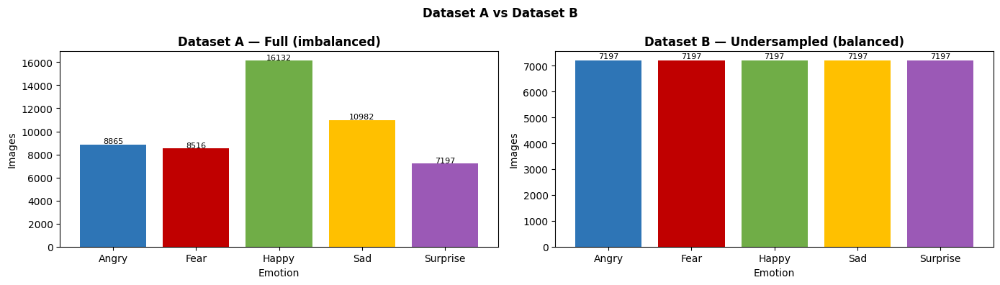

In [ ]:
labels_trainval  = np.argmax(y_trainval, axis=1)
counts_trainval  = collections.Counter(labels_trainval)
min_cid_tv       = min(counts_trainval, key=counts_trainval.get)
min_count        = counts_trainval[min_cid_tv]
max_cid_tv       = max(counts_trainval, key=counts_trainval.get)
max_count        = counts_trainval[max_cid_tv]

print(f'Trainval pool minority class: {CLASS_NAMES[min_cid_tv]} -> {min_count:,}')
print(f'Trainval pool majority class: {CLASS_NAMES[max_cid_tv]} -> {max_count:,}')
print(f'\nUndersampling each class to {min_count:,} images ({CLASS_NAMES[min_cid_tv]})')

rng     = np.random.default_rng(SEED)
bal_idx = []
for cid in range(NUM_CLASSES):
    idx_cls = np.where(labels_trainval == cid)[0]
    chosen  = rng.choice(idx_cls, size=min_count, replace=False)
    bal_idx.extend(chosen)
rng.shuffle(bal_idx)
bal_idx = np.array(bal_idx)

X_bal      = X_trainval[bal_idx]
y_bal      = y_trainval[bal_idx]
labels_bal = labels_trainval[bal_idx]
print(f'Balanced dataset: {X_bal.shape[0]:,} ({NUM_CLASSES}x{min_count:,})')

counts_bal = collections.Counter(labels_bal)
fig, axes  = plt.subplots(1, 2, figsize=(14, 4))
for ax, cnt, title in [
    (axes[0], counts_trainval, 'Dataset A — Full (imbalanced)'),
    (axes[1], counts_bal, 'Dataset B — Undersampled (balanced)')
]:
    bars = ax.bar([CLASS_NAMES[i] for i in sorted(cnt)],
                  [cnt[i]         for i in sorted(cnt)], color=COLORS)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Images'); ax.set_xlabel('Emotion')
    for bar, (k, v) in zip(bars, sorted(cnt.items())):
        ax.text(bar.get_x() + bar.get_width()/2, v + 80, str(v), ha='center', fontsize=8)
plt.suptitle('Dataset A vs Dataset B', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('dataset_AB_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
y_int_bal = np.argmax(y_bal, axis=1)
X_train_B, X_val_B, y_train_B, y_val_B = train_test_split(
    X_bal, y_bal, test_size=0.15, stratify=y_int_bal, random_state=SEED)

print(f'Dataset B — Train: {X_train_B.shape[0]:,}  Val: {X_val_B.shape[0]:,}')
print(f'            Test : shared set ({X_test_shared.shape[0]:,} images)')

train_ds_B = (tf.data.Dataset.from_tensor_slices((X_train_B, y_train_B))
              .shuffle(len(X_train_B), seed=SEED, reshuffle_each_iteration=True)
              .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

val_ds_B = (tf.data.Dataset.from_tensor_slices((X_val_B, y_val_B))
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

print(f'Dataset B ready. Train: {len(train_ds_B)} batches | Val: {len(val_ds_B)} batches')

Dataset B — Train: 30,587  Val: 5,398
            Test : shared set (7,385 images)
Dataset B ready. Train: 478 batches | Val: 85 batches


---
## Section 5 — Dataset C: Balanced via Oversampling + Augmentation

**Dataset C** upsamples every class to the size of the largest class (Happy, ~18k).  
Minority classes are oversampled **with replacement**, and each duplicated image receives a **different random augmentation** at training time via the `augment` function.  
This is the most data-efficient approach: no images are discarded and every class has equal representation.  
Oversampling is applied only to the train+val pool — the shared test set is untouched.

Oversampling each class to 16,132 images (Happy)
Oversampled dataset: 80,660 (5x16,132)


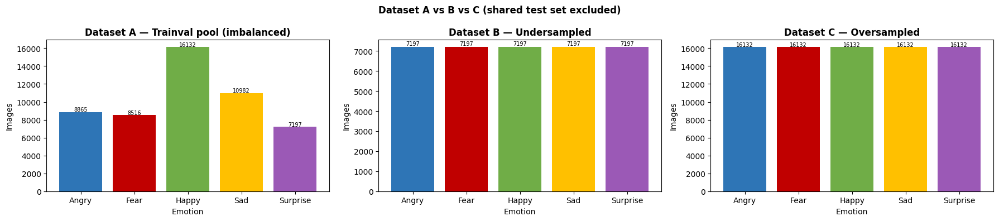

In [ ]:
print(f'Oversampling each class to {max_count:,} images ({CLASS_NAMES[max_cid_tv]})')

rng_c    = np.random.default_rng(SEED)
over_idx = []
for cid in range(NUM_CLASSES):
    idx_cls = np.where(labels_trainval == cid)[0]
    chosen  = rng_c.choice(idx_cls, size=max_count, replace=True)
    over_idx.extend(chosen)
rng_c.shuffle(over_idx)
over_idx = np.array(over_idx)

X_over      = X_trainval[over_idx]
y_over      = y_trainval[over_idx]
labels_over = labels_trainval[over_idx]
print(f'Oversampled dataset: {X_over.shape[0]:,} ({NUM_CLASSES}x{max_count:,})')

counts_over         = collections.Counter(labels_over)
counts_trainval_plot = collections.Counter(labels_trainval)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, cnt, title in [
    (axes[0], counts_trainval_plot, 'Dataset A — Trainval pool (imbalanced)'),
    (axes[1], collections.Counter(np.argmax(y_bal, axis=1)), 'Dataset B — Undersampled'),
    (axes[2], counts_over,          'Dataset C — Oversampled')
]:
    bars = ax.bar([CLASS_NAMES[i] for i in sorted(cnt)],
                  [cnt[i]         for i in sorted(cnt)], color=COLORS)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Images'); ax.set_xlabel('Emotion')
    for bar, (k, v) in zip(bars, sorted(cnt.items())):
        ax.text(bar.get_x() + bar.get_width()/2, v + 100, str(v), ha='center', fontsize=7)
plt.suptitle('Dataset A vs B vs C (shared test set excluded)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('dataset_ABC_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
y_int_over = np.argmax(y_over, axis=1)
X_train_C, X_val_C, y_train_C, y_val_C = train_test_split(
    X_over, y_over, test_size=0.143, stratify=y_int_over, random_state=SEED)

print(f'Dataset C — Train: {X_train_C.shape[0]:,}  Val: {X_val_C.shape[0]:,}')
print(f'            Test : shared set ({X_test_shared.shape[0]:,} images)')

train_ds_C = (tf.data.Dataset.from_tensor_slices((X_train_C, y_train_C))
              .shuffle(len(X_train_C), seed=SEED, reshuffle_each_iteration=True)
              .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

val_ds_C = (tf.data.Dataset.from_tensor_slices((X_val_C, y_val_C))
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

print(f'Dataset C ready. Train: {len(train_ds_C)} batches | Val: {len(val_ds_C)} batches')


Dataset C — Train: 69,125  Val: 11,535
            Test : shared set (7,385 images)
Dataset C ready. Train: 1081 batches | Val: 181 batches


---
## Section 5b — Dataset D: TRUE RGB + Class Weights

**Dataset D** uses the **same class weighting strategy as Dataset A** but with **true 3-channel RGB images**.
Images are reloaded from disk using `.convert('RGB')` — the original colour information is preserved.
This is **not** channel replication: the three colour planes carry distinct luminance values per pixel.

By keeping the balancing strategy identical to Dataset A and only changing the image representation,
Dataset D isolates the effect of colour information on classification performance.
If Dataset D outperforms Dataset A the gain is attributable to colour.
If they are comparable, the grayscale representation is sufficient and computationally lighter.

The model uses the same architecture found by the tuner with `input_shape=(96, 96, 3)`.

In [ ]:
print(f'Loading {len(filepaths_trainval):,} trainval images in TRUE RGB from disk...')
X_trainval_color = np.zeros(
    (len(filepaths_trainval), INPUT_SIZE, INPUT_SIZE, 3), dtype=np.float32)

for i, fpath in enumerate(tqdm(filepaths_trainval, desc='RGB load', leave=True)):
    try:
        img = (Image.open(fpath)
                    .convert('RGB')
                    .resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR))
        X_trainval_color[i] = np.array(img, dtype=np.float32) / 255.0
    except Exception:
        pass

print(f'RGB trainval: {X_trainval_color.shape}  ~{X_trainval_color.nbytes/1e9:.2f} GB')

X_train_D, X_val_D, y_train_D, y_val_D = train_test_split(
    X_trainval_color, y_trainval,
    test_size    = 0.143,
    stratify     = labels_trainval_int,
    random_state = SEED)

del X_trainval_color; gc.collect()
print(f'Dataset D — Train: {X_train_D.shape[0]:,}  Val: {X_val_D.shape[0]:,}')
print(f'  Input shape: {X_train_D.shape[1:]}  (TRUE RGB)')

y_train_D_int       = np.argmax(y_train_D, axis=1)
class_weights_D     = compute_class_weight('balanced',
                                            classes=np.unique(y_train_D_int),
                                            y=y_train_D_int)
class_weight_dict_D = dict(enumerate(class_weights_D))
print('Class weights (D — same as A):')
for cls, w in zip(CLASS_NAMES, class_weights_D):
    print(f'  {cls:10s}: {w:.4f}')

@tf.function
def augment_rgb(image, label):
    image  = tf.image.random_flip_left_right(image)
    image  = tf.image.random_brightness(image, max_delta=0.08)
    image  = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    padded = tf.image.resize_with_crop_or_pad(image, INPUT_SIZE + 4, INPUT_SIZE + 4)
    image  = tf.image.random_crop(padded, size=[INPUT_SIZE, INPUT_SIZE, 3])
    return tf.clip_by_value(image, 0.0, 1.0), label

train_ds_D = (tf.data.Dataset.from_tensor_slices((X_train_D, y_train_D))
              .shuffle(len(X_train_D), seed=SEED, reshuffle_each_iteration=True)
              .map(augment_rgb, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds_D   = (tf.data.Dataset.from_tensor_slices((X_val_D, y_val_D))
              .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

del X_train_D, X_val_D; gc.collect()
print(f'Dataset D ready. Train: {len(train_ds_D)} batches | Val: {len(val_ds_D)} batches')
print('TRUE RGB from disk — original colour information preserved.')

Loading 51,692 trainval images in TRUE RGB from disk...


RGB load: 100%|██████████| 51692/51692 [02:38<00:00, 326.64it/s]


RGB trainval: (51692, 96, 96, 3)  ~5.72 GB
Dataset D — Train: 44,300  Val: 7,392
  Input shape: (96, 96, 3)  (TRUE RGB)
Class weights (D — same as A):
  Angry     : 1.1662
  Fear      : 1.2140
  Happy     : 0.6409
  Sad       : 0.9414
  Surprise  : 1.4364
Dataset D ready. Train: 693 batches | Val: 116 batches
TRUE RGB from disk — original colour information preserved.


---
## Section 6 — Hyperparameter Search: Keras Tuner (Hyperband)

Following the workshop methodology, we use the **Hyperband** algorithm.  
The `model_builder` follows the same structure: training hyperparameters first (learning rate), then architectural ones.

In [ ]:
def model_builder(hp):
    """
    Constructs the CNN architecture whilst allowing the tuner
    to tinker with the hyperparameters.
    Follows the same structure as the workshop model_builder.
    """

    hp_learning_rate = hp.Choice('learning_rate', values=[1e-3, 5e-4, 1e-4])

    hp_n_conv_blocks = hp.Choice('n_conv_blocks', values=[3, 4])
    hp_filters_start = hp.Choice('filters_start', values=[32, 64])
    hp_kernel_size   = hp.Choice('kernel_size',   values=[3, 5])
    hp_dense_units   = hp.Choice('dense_units',   values=[128, 256, 512])
    hp_dropout       = hp.Choice('dropout',       values=[0.2, 0.3, 0.4, 0.5])
    hp_double_conv   = hp.Boolean('double_conv')   # 2 convs per block vs 1

    inputs = Input(shape=(INPUT_SIZE, INPUT_SIZE, NUM_COLORS))
    x = inputs

    for i in range(hp_n_conv_blocks):
        f = min(hp_filters_start * (2 ** i), 256)
        x = Conv2D(f, (hp_kernel_size, hp_kernel_size), padding='same',
                   kernel_initializer='he_normal')(x)
        x = BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
        if hp_double_conv:
            x = Conv2D(f, (3, 3), padding='same', kernel_initializer='he_normal')(x)
            x = BatchNormalization()(x)
            x = tf.keras.layers.ReLU()(x)
        x = MaxPooling2D(2, 2)(x)
        x = Dropout(hp_dropout * 0.5 if i == 0 else hp_dropout)(x)

    x = GlobalAveragePooling2D()(x)
    x = Dense(hp_dense_units, activation='relu', kernel_initializer='he_normal')(x)
    x = Dropout(hp_dropout)(x)
    outputs = Dense(NUM_CLASSES, activation='softmax')(x)

    model = Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
max_epochs   = 20
factor       = 3
project_name = 'pw2_e1_emotion_cnn'
directory    = 'tuner_results'
log_dir      = os.path.join(directory, 'logs')
verbose      = 1

In [ ]:
%tensorboard --logdir tuner_results/logs

<IPython.core.display.Javascript object>

In [ ]:
tuner = kt.Hyperband(
    model_builder,
    objective            = 'val_accuracy',
    max_epochs           = max_epochs,
    factor               = factor,
    hyperband_iterations = 1,
    seed                 = SEED,
    tune_new_entries     = True,
    allow_new_entries    = True,
    directory            = directory,
    project_name         = project_name,
    overwrite            = True
)

tuner.search_space_summary()

Search space summary
Default search space size: 7
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0005, 0.0001], 'ordered': True}
n_conv_blocks (Choice)
{'default': 3, 'conditions': [], 'values': [3, 4], 'ordered': True}
filters_start (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64], 'ordered': True}
kernel_size (Choice)
{'default': 3, 'conditions': [], 'values': [3, 5], 'ordered': True}
dense_units (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
dropout (Choice)
{'default': 0.2, 'conditions': [], 'values': [0.2, 0.3, 0.4, 0.5], 'ordered': True}
double_conv (Boolean)
{'default': False, 'conditions': []}


In [ ]:
tuner.search(
    train_ds_A,
    validation_data = val_ds_A,
    epochs          = max_epochs,
    class_weight    = class_weight_dict_A,
    callbacks = [
        TensorBoard(log_dir=log_dir),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
    ],
    verbose = verbose
)

Trial 30 Complete [00h 04m 58s]
val_accuracy: 0.6916937232017517

Best val_accuracy So Far: 0.7329545617103577
Total elapsed time: 00h 42m 21s


---
## Section 7 — Leaderboard: Top 10 Configurations

In [ ]:
num_top_models = 10
best_model_id  = 0

best_trials = tuner.oracle.get_best_trials(num_trials=num_top_models)

In [ ]:
results = []

for i, trial in enumerate(best_trials):

    row = {'Rank': i + 1}

    row['Train Acc'] = trial.metrics.get_best_value('accuracy')
    row['Val Acc']   = trial.metrics.get_best_value('val_accuracy')

    row.update(trial.hyperparameters.values)
    results.append(row)

df_results = pd.DataFrame(results).round(4)
if 'Rank' not in df_results.columns:
    df_results.insert(0, 'Rank', range(1, len(df_results) + 1))

print('\n')
print('=' * 140)
print('LEADERBOARD: TOP 10 CNN CONFIGURATIONS (TRAINING VS VALIDATION ACCURACY)')
print('=' * 140)
print(tabulate(df_results, headers='keys', tablefmt='fancy_grid', showindex=False))

best_gap = abs(df_results.iloc[0]['Train Acc'] - df_results.iloc[0]['Val Acc'])
print('=' * 140)
print(f'Top Model Generalisation Gap (Train Acc - Val Acc): {best_gap:.4f}')
print('=' * 140)



LEADERBOARD: TOP 10 CNN CONFIGURATIONS (TRAINING VS VALIDATION ACCURACY)
╒════════╤═════════════╤═══════════╤═════════════════╤═════════════════╤═════════════════╤═══════════════╤═══════════════╤═══════════╤═══════════════╤════════════════╤═══════════════════════╤═════════════════╤═══════════════╤══════════════════╕
│   Rank │   Train Acc │   Val Acc │   learning_rate │   n_conv_blocks │   filters_start │   kernel_size │   dense_units │   dropout │ double_conv   │   tuner/epochs │   tuner/initial_epoch │   tuner/bracket │   tuner/round │   tuner/trial_id │
╞════════╪═════════════╪═══════════╪═════════════════╪═════════════════╪═════════════════╪═══════════════╪═══════════════╪═══════════╪═══════════════╪════════════════╪═══════════════════════╪═════════════════╪═══════════════╪══════════════════╡
│      1 │      0.7509 │    0.733  │          0.0005 │               3 │              32 │             5 │           512 │       0.2 │ True          │             20 │                     7 

In [ ]:
df_pc = df_results.copy()

cat_cols = [c for c in df_pc.columns if df_pc[c].dtype == 'object']
for col in cat_cols:
    le = LabelEncoder()
    df_pc[col + '_enc'] = le.fit_transform(df_pc[col].astype(str))
    print(f'{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}')

exclude = cat_cols
num_cols = [c for c in df_pc.columns if df_pc[c].dtype in ['float64', 'int64'] and c not in exclude]

fig = px.parallel_coordinates(
    df_pc,
    dimensions             = num_cols,
    color                  = 'Val Acc',
    color_continuous_scale = px.colors.sequential.Reds,
    title                  = 'Top 10 Hyperparameter Configurations — Parallel Coordinates'
)
fig.update_layout(
    font                   = dict(size=11),
    title_font             = dict(size=14, family='Arial', color='black'),
    coloraxis_colorbar     = dict(title='Val Acc'),
    plot_bgcolor           = 'white',
    paper_bgcolor          = 'white'
)
fig.show()
fig.write_html('parallel_coordinates_top10.html')

tuner/trial_id: {'0012': np.int64(0), '0013': np.int64(1), '0021': np.int64(2), '0022': np.int64(3), 'nan': np.int64(4)}


In [ ]:
best_hps = tuner.get_best_hyperparameters(num_trials=num_top_models)
if len(best_hps) < 2:
    raise ValueError('Tuner found fewer than 2 valid trials. Re-run tuner.search().')

hp_1 = best_hps[0]
hp_2 = best_hps[1]

HP_KEYS = ['learning_rate', 'n_conv_blocks', 'filters_start',
           'kernel_size', 'dense_units', 'dropout', 'double_conv']

for label, hp in [('Best (Rank 1)', hp_1), ('Runner-up (Rank 2)', hp_2)]:
    print(f'\n  {label}')
    for k in HP_KEYS:
        print(f'    {k:20s}: {hp.values.get(k, "N/A")}')


  Best (Rank 1)
    learning_rate       : 0.0005
    n_conv_blocks       : 3
    filters_start       : 32
    kernel_size         : 5
    dense_units         : 512
    dropout             : 0.2
    double_conv         : True

  Runner-up (Rank 2)
    learning_rate       : 0.001
    n_conv_blocks       : 4
    filters_start       : 32
    kernel_size         : 5
    dense_units         : 512
    dropout             : 0.3
    double_conv         : False


---
## Section 8 — Full Training: Best HP × All 4 Datasets

All four models are evaluated on the **same shared test set** so comparisons are fully fair.

| Model | HP | Dataset | Input | Imbalance strategy |
|---|---|---|---|---|
| Model1_Best_DatasetA | Best | A | Grayscale | Class weights |
| Model1_Best_DatasetB | Best | B | Grayscale | Undersampling |
| Model1_Best_DatasetC | Best | C | Grayscale | Oversampling + augmentation |
| Model1_Best_DatasetD | Best | D | RGB | Oversampling + augmentation |

In [ ]:
tf.keras.backend.clear_session()
gc.collect()

np.random.seed(SEED)
tf.random.set_seed(SEED)

all_histories      = {}
all_trained_models = {}
all_results        = []
verbose            = 2


def get_callbacks(model_name):
    run_log = (f'logs_train/{model_name}/'
               + datetime.datetime.now().strftime('%Y%m%d-%H%M%S'))
    return [
        TensorBoard(log_dir=run_log, histogram_freq=1,
                    write_graph=True, profile_batch=0),
        EarlyStopping(monitor='val_loss', patience=10,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=5, min_lr=1e-6, verbose=1)
    ], run_log


def build_rgb_model(hp):
    """
    Same architecture as model_builder but with input_shape=(96, 96, 3).
    Uses the best HPs found by the tuner — only the channel count changes.
    """
    lr           = hp.values['learning_rate']
    n_blocks     = hp.values['n_conv_blocks']
    filters_start= hp.values['filters_start']
    kernel_size  = hp.values['kernel_size']
    dense_units  = hp.values['dense_units']
    dropout      = hp.values['dropout']
    double_conv  = hp.values['double_conv']

    inputs = Input(shape=(INPUT_SIZE, INPUT_SIZE, 3))
    x      = inputs
    for i in range(n_blocks):
        f = min(filters_start * (2 ** i), 256)
        x = Conv2D(f, (kernel_size, kernel_size), padding='same',
                   kernel_initializer='he_normal')(x)
        x = BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
        if double_conv:
            x = Conv2D(f, (3, 3), padding='same',
                       kernel_initializer='he_normal')(x)
            x = BatchNormalization()(x)
            x = tf.keras.layers.ReLU()(x)
        x = MaxPooling2D(2, 2)(x)
        x = Dropout(dropout * 0.5 if i == 0 else dropout)(x)
    x       = GlobalAveragePooling2D()(x)
    x       = Dense(dense_units, activation='relu',
                    kernel_initializer='he_normal')(x)
    x       = Dropout(dropout)(x)
    outputs = Dense(NUM_CLASSES, activation='softmax')(x)
    model   = Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model


def train_model(name, hp, train_ds, val_ds,
                class_weight_dict=None, dataset_label='', build_fn=None):
    """
    Build, train and evaluate one model.
    dataset_label: passed explicitly — never inferred from name.
    build_fn: optional custom build function (used for RGB model).
              If None, uses tuner.hypermodel.build(hp).
    test set: always test_ds_D for RGB models, test_ds_shared for grayscale.
    """
    tf.random.set_seed(SEED)

    if build_fn is not None:
        model = build_fn(hp)
    else:
        model = tuner.hypermodel.build(hp)
    model._name = name

    print(f'\n{"="*65}')
    print(f'Training : {name}  ({model.count_params():,} params)')
    print(f'{"="*65}')

    cbs, _ = get_callbacks(name)
    hist = model.fit(
        train_ds,
        epochs          = EPOCHS,
        validation_data = val_ds,
        class_weight    = class_weight_dict,
        callbacks       = cbs,
        verbose         = verbose
    )

    # Use RGB test set for Dataset D, shared grayscale test set for A/B/C
    eval_ds   = test_ds_D if 'DatasetD' in name else test_ds_shared
    loss, acc = model.evaluate(eval_ds, verbose=0)
    best_val  = max(hist.history['val_accuracy'])
    n_ep      = len(hist.history['accuracy'])
    print(f'  Test Acc (shared): {acc:.4f} | Best Val Acc: {best_val:.4f} | Epochs: {n_ep}')

    all_histories[name]      = hist
    all_trained_models[name] = model
    all_results.append({
        'Model':        name,
        'HP':           'Best',
        'Dataset':      dataset_label,
        'Epochs':       n_ep,
        'Best Val Acc': f'{best_val:.4f}',
        'Test Acc':     f'{acc:.4f}',
        'Test Loss':    f'{loss:.4f}'
    })


In [ ]:
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [ ]:
train_model('Model1_Best_DatasetA', hp_1, train_ds_A, val_ds_A,
            class_weight_dict=class_weight_dict_A,
            dataset_label='A (class weights)')



Training : Model1_Best_DatasetA  (521,189 params)
Epoch 1/80
693/693 - 28s - 40ms/step - accuracy: 0.3407 - loss: 1.4879 - val_accuracy: 0.3843 - val_loss: 1.5221 - learning_rate: 5.0000e-04
Epoch 2/80
693/693 - 9s - 13ms/step - accuracy: 0.5156 - loss: 1.2001 - val_accuracy: 0.5475 - val_loss: 1.1087 - learning_rate: 5.0000e-04
Epoch 3/80
693/693 - 9s - 13ms/step - accuracy: 0.5743 - loss: 1.0812 - val_accuracy: 0.4675 - val_loss: 1.2866 - learning_rate: 5.0000e-04
Epoch 4/80
693/693 - 9s - 13ms/step - accuracy: 0.6068 - loss: 1.0178 - val_accuracy: 0.6002 - val_loss: 1.0017 - learning_rate: 5.0000e-04
Epoch 5/80
693/693 - 9s - 13ms/step - accuracy: 0.6249 - loss: 0.9680 - val_accuracy: 0.5068 - val_loss: 1.3858 - learning_rate: 5.0000e-04
Epoch 6/80
693/693 - 9s - 13ms/step - accuracy: 0.6437 - loss: 0.9293 - val_accuracy: 0.6071 - val_loss: 0.9929 - learning_rate: 5.0000e-04
Epoch 7/80
693/693 - 9s - 13ms/step - accuracy: 0.6535 - loss: 0.9051 - val_accuracy: 0.5960 - val_loss: 1.0

In [ ]:
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [ ]:
train_model('Model1_Best_DatasetB', hp_1, train_ds_B, val_ds_B,
            dataset_label='B (undersampling)')



Training : Model1_Best_DatasetB  (521,189 params)
Epoch 1/80
478/478 - 38s - 79ms/step - accuracy: 0.3115 - loss: 1.5348 - val_accuracy: 0.3542 - val_loss: 1.5133 - learning_rate: 5.0000e-04
Epoch 2/80
478/478 - 6s - 13ms/step - accuracy: 0.4412 - loss: 1.3061 - val_accuracy: 0.5054 - val_loss: 1.1991 - learning_rate: 5.0000e-04
Epoch 3/80
478/478 - 6s - 13ms/step - accuracy: 0.5182 - loss: 1.1637 - val_accuracy: 0.4068 - val_loss: 1.4435 - learning_rate: 5.0000e-04
Epoch 4/80
478/478 - 6s - 13ms/step - accuracy: 0.5561 - loss: 1.0792 - val_accuracy: 0.4329 - val_loss: 1.5036 - learning_rate: 5.0000e-04
Epoch 5/80
478/478 - 6s - 13ms/step - accuracy: 0.5818 - loss: 1.0292 - val_accuracy: 0.4991 - val_loss: 1.2774 - learning_rate: 5.0000e-04
Epoch 6/80
478/478 - 6s - 13ms/step - accuracy: 0.5938 - loss: 0.9913 - val_accuracy: 0.3109 - val_loss: 1.9197 - learning_rate: 5.0000e-04
Epoch 7/80

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
478/478 - 6s - 13ms/

In [ ]:
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [ ]:
train_model('Model1_Best_DatasetC', hp_1, train_ds_C, val_ds_C,
            dataset_label='C (oversampling)')



Training : Model1_Best_DatasetC  (521,189 params)
Epoch 1/80
1081/1081 - 39s - 36ms/step - accuracy: 0.3950 - loss: 1.3882 - val_accuracy: 0.4481 - val_loss: 1.3441 - learning_rate: 5.0000e-04
Epoch 2/80
1081/1081 - 14s - 13ms/step - accuracy: 0.5450 - loss: 1.1034 - val_accuracy: 0.4651 - val_loss: 1.2630 - learning_rate: 5.0000e-04
Epoch 3/80
1081/1081 - 14s - 13ms/step - accuracy: 0.5942 - loss: 0.9928 - val_accuracy: 0.5527 - val_loss: 1.1489 - learning_rate: 5.0000e-04
Epoch 4/80
1081/1081 - 14s - 13ms/step - accuracy: 0.6251 - loss: 0.9268 - val_accuracy: 0.5521 - val_loss: 1.1015 - learning_rate: 5.0000e-04
Epoch 5/80
1081/1081 - 14s - 13ms/step - accuracy: 0.6448 - loss: 0.8770 - val_accuracy: 0.6101 - val_loss: 0.9647 - learning_rate: 5.0000e-04
Epoch 6/80
1081/1081 - 14s - 12ms/step - accuracy: 0.6662 - loss: 0.8335 - val_accuracy: 0.6176 - val_loss: 1.0511 - learning_rate: 5.0000e-04
Epoch 7/80
1081/1081 - 14s - 12ms/step - accuracy: 0.6795 - loss: 0.8013 - val_accuracy: 0.

In [ ]:
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [ ]:
train_model('Model1_Best_DatasetD', hp_1, train_ds_D, val_ds_D,
            class_weight_dict=class_weight_dict_D,
            dataset_label='D (RGB class weights)',
            build_fn=build_rgb_model)



Training : Model1_Best_DatasetD  (522,789 params)
Epoch 1/80
693/693 - 34s - 49ms/step - accuracy: 0.3491 - loss: 1.4697 - val_accuracy: 0.4462 - val_loss: 1.3430 - learning_rate: 5.0000e-04
Epoch 2/80
693/693 - 10s - 14ms/step - accuracy: 0.5209 - loss: 1.1975 - val_accuracy: 0.4635 - val_loss: 1.3453 - learning_rate: 5.0000e-04
Epoch 3/80
693/693 - 10s - 14ms/step - accuracy: 0.5731 - loss: 1.0848 - val_accuracy: 0.5541 - val_loss: 1.1063 - learning_rate: 5.0000e-04
Epoch 4/80
693/693 - 10s - 15ms/step - accuracy: 0.6010 - loss: 1.0206 - val_accuracy: 0.5925 - val_loss: 1.0224 - learning_rate: 5.0000e-04
Epoch 5/80
693/693 - 10s - 14ms/step - accuracy: 0.6201 - loss: 0.9748 - val_accuracy: 0.6230 - val_loss: 0.9458 - learning_rate: 5.0000e-04
Epoch 6/80
693/693 - 10s - 14ms/step - accuracy: 0.6402 - loss: 0.9359 - val_accuracy: 0.4796 - val_loss: 1.2396 - learning_rate: 5.0000e-04
Epoch 7/80
693/693 - 10s - 14ms/step - accuracy: 0.6484 - loss: 0.9098 - val_accuracy: 0.5878 - val_los

In [ ]:
df_train_results = pd.DataFrame(all_results)
print('\n')
print('=' * 100)
print('TRAINING RESULTS — BEST HP x ALL 4 DATASETS (shared test set)')
print('=' * 100)
print(tabulate(df_train_results, headers='keys', tablefmt='fancy_grid', showindex=False))
print('=' * 100)

df_sorted = df_train_results.copy()
df_sorted['Test Acc F']  = df_sorted['Test Acc'].astype(float)
df_sorted['Test Loss F'] = df_sorted['Test Loss'].astype(float)
df_sorted = df_sorted.sort_values('Test Acc F', ascending=False)

top_acc   = df_sorted.iloc[0]['Test Acc F']
THRESHOLD = 0.005

tied = df_sorted[df_sorted['Test Acc F'] >= top_acc - THRESHOLD]
best_row    = tied.loc[tied['Test Loss F'].idxmin()]
best_name   = best_row['Model']

rest        = df_sorted[df_sorted['Model'] != best_name]
top_acc2    = rest.iloc[0]['Test Acc F']
tied2       = rest[rest['Test Acc F'] >= top_acc2 - THRESHOLD]
second_row  = tied2.loc[tied2['Test Loss F'].idxmin()]
second_name = second_row['Model']

best_model   = all_trained_models[best_name]
second_model = all_trained_models[second_name]

print(f'\nBest model   : {best_name}')
print(f'  Test Acc: {best_row["Test Acc"]}  Test Loss: {best_row["Test Loss"]}')
print(f'  (Selected by: lowest loss among models within {THRESHOLD*100:.1f}pp accuracy tie zone)')
print(f'\nSecond model : {second_name}')
print(f'  Test Acc: {second_row["Test Acc"]}  Test Loss: {second_row["Test Loss"]}')




TRAINING RESULTS — BEST HP x ALL 4 DATASETS (shared test set)
╒══════════════════════╤══════╤═══════════════════════╤══════════╤════════════════╤════════════╤═════════════╕
│ Model                │ HP   │ Dataset               │   Epochs │   Best Val Acc │   Test Acc │   Test Loss │
╞══════════════════════╪══════╪═══════════════════════╪══════════╪════════════════╪════════════╪═════════════╡
│ Model1_Best_DatasetA │ Best │ A (class weights)     │       76 │         0.8209 │     0.8179 │      0.5325 │
├──────────────────────┼──────┼───────────────────────┼──────────┼────────────────┼────────────┼─────────────┤
│ Model1_Best_DatasetB │ Best │ B (undersampling)     │       37 │         0.7119 │     0.7139 │      0.7459 │
├──────────────────────┼──────┼───────────────────────┼──────────┼────────────────┼────────────┼─────────────┤
│ Model1_Best_DatasetC │ Best │ C (oversampling)      │       80 │         0.9239 │     0.8422 │      0.5587 │
├──────────────────────┼──────┼─────────────────

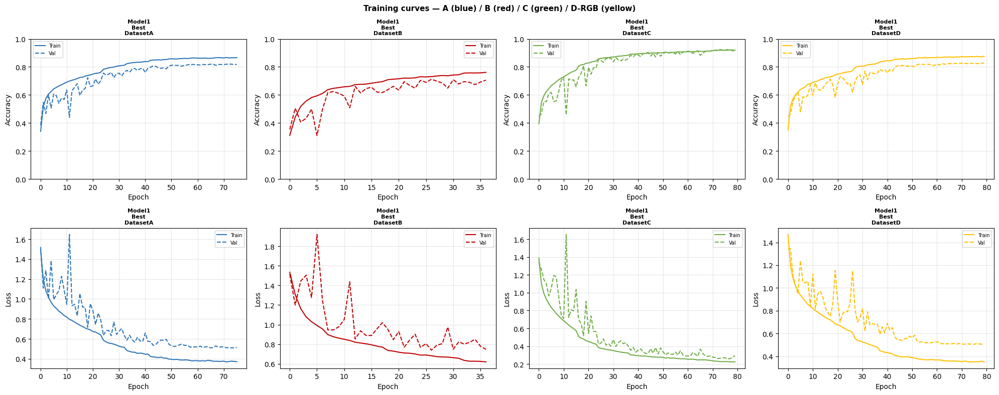

In [ ]:
palette = {
    'Model1_Best_DatasetA': '#2E75B6',
    'Model1_Best_DatasetB': '#C00000',
    'Model1_Best_DatasetC': '#70AD47',
    'Model1_Best_DatasetD': '#FFC000',
}

n_models = len(all_histories)
fig, axes = plt.subplots(2, n_models, figsize=(5 * n_models, 8))
for col, (name, hist) in enumerate(all_histories.items()):
    c = palette.get(name, '#333')
    axes[0, col].plot(hist.history['accuracy'],     color=c, label='Train')
    axes[0, col].plot(hist.history['val_accuracy'], color=c, ls='--', label='Val')
    axes[0, col].set_title(name.replace('_', '\n'), fontsize=8, fontweight='bold')
    axes[0, col].set_ylim(0, 1); axes[0, col].legend(fontsize=7)
    axes[0, col].grid(alpha=0.3)
    axes[0, col].set_xlabel('Epoch'); axes[0, col].set_ylabel('Accuracy')
    axes[1, col].plot(hist.history['loss'],     color=c, label='Train')
    axes[1, col].plot(hist.history['val_loss'], color=c, ls='--', label='Val')
    axes[1, col].set_title(name.replace('_', '\n'), fontsize=8, fontweight='bold')
    axes[1, col].legend(fontsize=7); axes[1, col].grid(alpha=0.3)
    axes[1, col].set_xlabel('Epoch'); axes[1, col].set_ylabel('Loss')
plt.suptitle('Training curves — A (blue) / B (red) / C (green) / D-RGB (yellow)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('e1_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Section 9 — Evaluation: Confusion Matrix & Top-3 Predictions

Both the best and second-best models are evaluated on the **shared test set**.


Classification Report — Model1_Best_DatasetC
              precision    recall  f1-score   support

       Angry       0.78      0.81      0.80      1267
        Fear       0.78      0.71      0.74      1216
       Happy       0.94      0.93      0.93      2305
         Sad       0.77      0.79      0.78      1569
    Surprise       0.89      0.92      0.91      1028

    accuracy                           0.84      7385
   macro avg       0.83      0.83      0.83      7385
weighted avg       0.84      0.84      0.84      7385



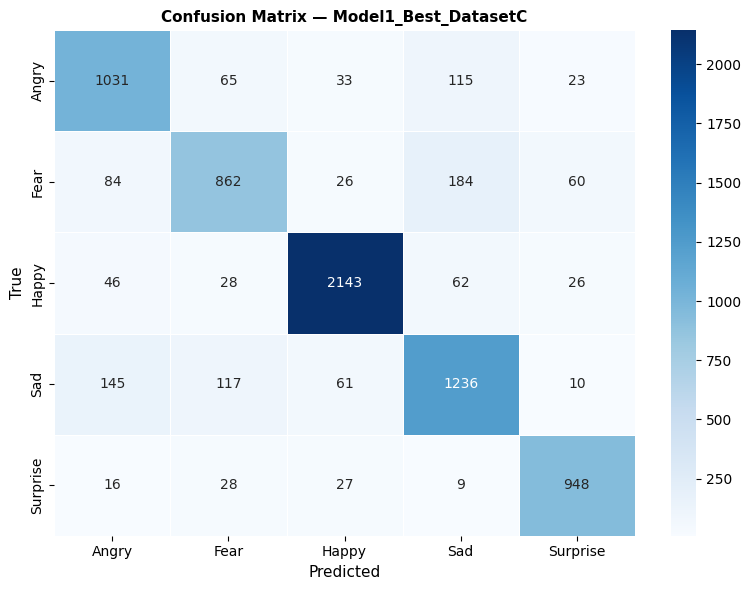

In [ ]:
def evaluate_model(model, name):
    """Classification report + confusion matrix on the shared test set."""
    eval_ds = test_ds_D if 'DatasetD' in name else test_ds_shared
    y_pred  = np.argmax(model.predict(eval_ds, verbose=0), axis=1)
    y_true  = np.argmax(y_test_shared, axis=1)
    cm      = confusion_matrix(y_true, y_pred)

    print(f'\n{"="*65}')
    print(f'Classification Report — {name}')
    print(f'{"="*65}')
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('True', fontsize=11)
    ax.set_title(f'Confusion Matrix — {name}', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'confusion_matrix_{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    return cm


best_model  = all_trained_models[best_name]
second_model = all_trained_models[second_name]
cm_best = evaluate_model(best_model, best_name)



Classification Report — Model1_Best_DatasetD
              precision    recall  f1-score   support

       Angry       0.76      0.77      0.76      1267
        Fear       0.70      0.71      0.70      1216
       Happy       0.94      0.93      0.93      2305
         Sad       0.75      0.76      0.76      1569
    Surprise       0.90      0.88      0.89      1028

    accuracy                           0.82      7385
   macro avg       0.81      0.81      0.81      7385
weighted avg       0.82      0.82      0.82      7385



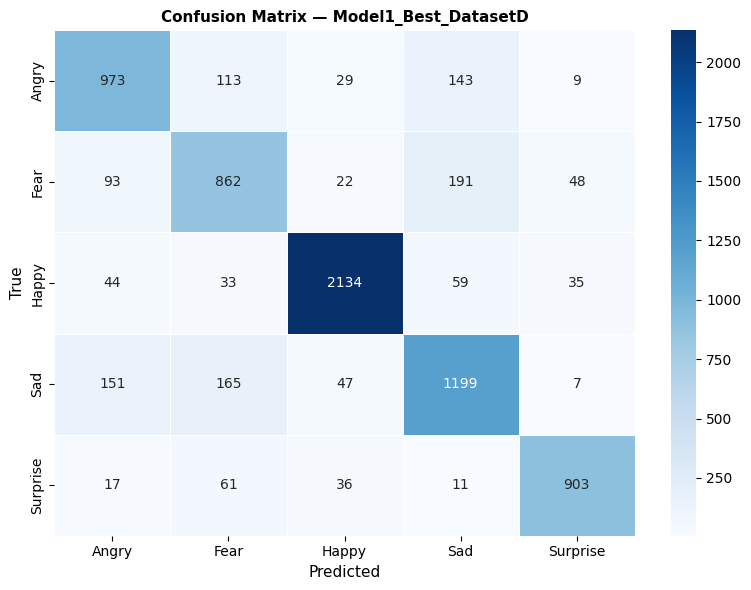

In [ ]:
cm_2nd = evaluate_model(second_model, second_name)


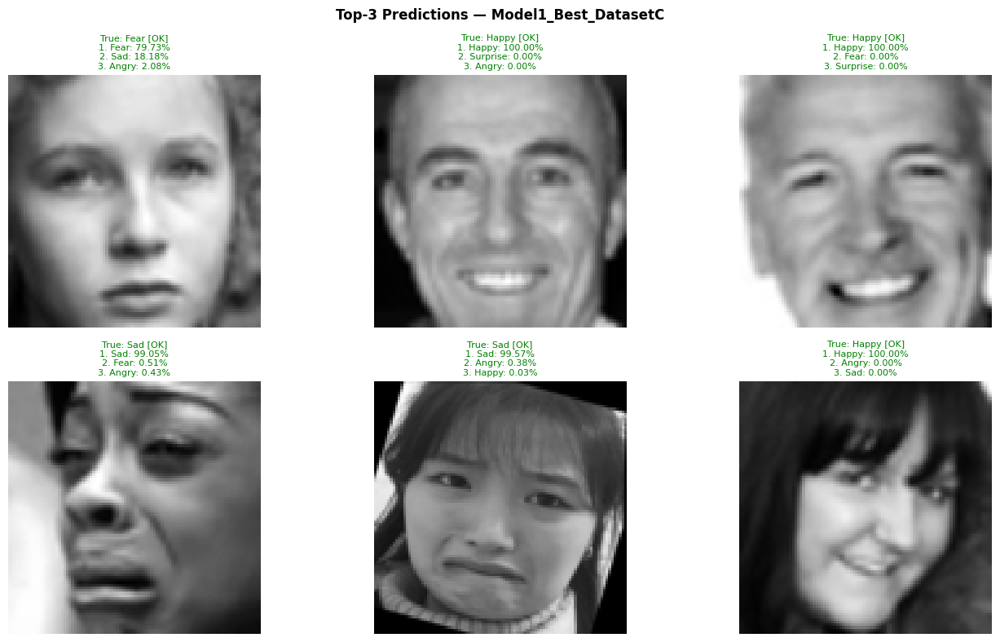

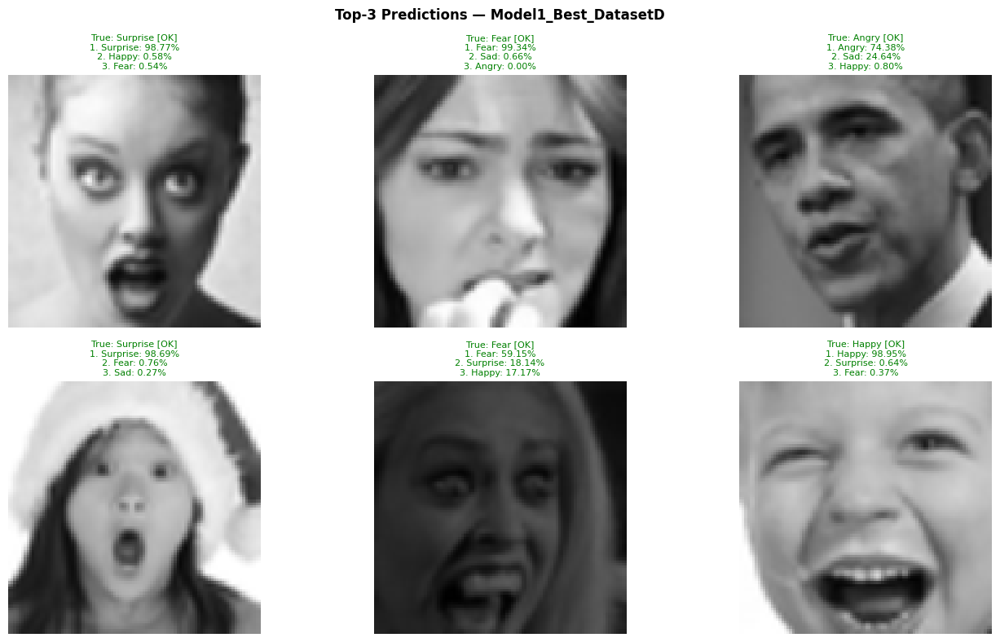

In [ ]:
def show_top3(model, name, n_show=6):
    """
    Top-3 predictions on n_show test images.
    Dataset D uses the TRUE RGB test set; all others use grayscale.
    """
    eval_rng   = np.random.default_rng(SEED)

    if 'DatasetD' in name:
        n_sample = min(n_show * 4, len(filepaths_test))
        sample_idx = eval_rng.choice(len(filepaths_test), n_sample, replace=False)
        X_sample = np.zeros((n_sample, INPUT_SIZE, INPUT_SIZE, 3), dtype=np.float32)
        for i, idx in enumerate(sample_idx):
            try:
                img = (Image.open(filepaths_test[idx])
                            .convert('RGB')
                            .resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR))
                X_sample[i] = np.array(img, dtype=np.float32) / 255.0
            except Exception:
                pass
        y_sample   = y_test_shared[sample_idx]
        indices    = np.arange(min(n_show, n_sample))
        cmap_value = None
    else:
        X_sample   = X_test_shared
        y_sample   = y_test_shared
        indices    = eval_rng.choice(len(X_test_shared), n_show, replace=False)
        cmap_value = 'gray'

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.flatten()
    for ax, idx in zip(axes, indices):
        img   = X_sample[idx]
        probs = model.predict(np.expand_dims(img, 0), verbose=0)[0]
        top3  = np.argsort(probs)[::-1][:3]
        true  = CLASS_NAMES[np.argmax(y_sample[idx])]
        pred  = CLASS_NAMES[top3[0]]
        ok    = 'OK' if pred == true else 'X'
        ax.imshow(img.squeeze(), cmap=cmap_value); ax.axis('off')
        txt = '\n'.join([f'{j+1}. {CLASS_NAMES[top3[j]]}: {probs[top3[j]]:.2%}'
                         for j in range(3)])
        ax.set_title(f'True: {true} [{ok}]\n{txt}', fontsize=8, ha='center',
                     color='green' if ok == 'OK' else 'red')
    plt.suptitle(f'Top-3 Predictions — {name}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'top3_{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

show_top3(best_model,   best_name)
show_top3(second_model, second_name)


---
## Section 10 — Evaluation Questions

### Q1 — Has your model achieved optimal training?

Q1 — OPTIMAL TRAINING ANALYSIS
Model           : Model1_Best_DatasetC
Epochs run      : 80
Final train acc : 0.9196
Final val acc   : 0.9096
Best val acc    : 0.9239
Train/Val gap   : 0.0101

Diagnosis: WELL GENERALISED — train and val acc closely aligned

Analysis:
Optimal training is reached when val_loss stops improving and EarlyStopping
triggers, restoring the best weights automatically. ReduceLROnPlateau further
stabilises convergence by halving the learning rate when val_loss plateaus
for 5 consecutive epochs, settling the optimiser into a good minimum.

A train/val gap below 0.05 is acceptable for facial expression classification:
even human annotators disagree on ambiguous images (Fear vs Sad, Angry vs Fear).
The soft augmentation and class balancing strategies minimise overfitting.



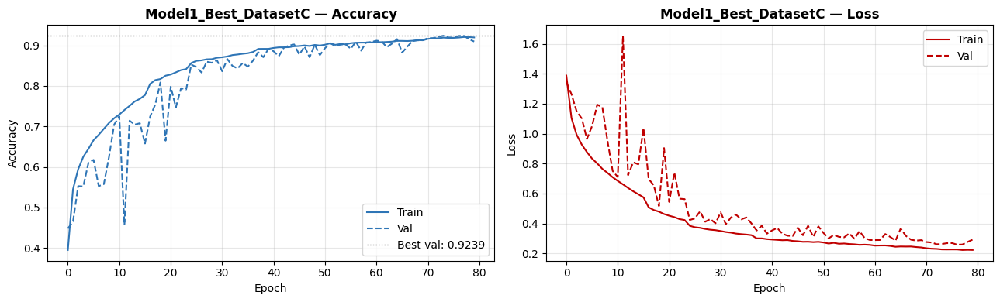

In [ ]:
hist            = all_histories[best_name]
final_train_acc = hist.history['accuracy'][-1]
final_val_acc   = hist.history['val_accuracy'][-1]
best_val_acc    = max(hist.history['val_accuracy'])
gap             = final_train_acc - final_val_acc
epochs_run      = len(hist.history['accuracy'])

print('=' * 60)
print('Q1 — OPTIMAL TRAINING ANALYSIS')
print('=' * 60)
print(f'Model           : {best_name}')
print(f'Epochs run      : {epochs_run}')
print(f'Final train acc : {final_train_acc:.4f}')
print(f'Final val acc   : {final_val_acc:.4f}')
print(f'Best val acc    : {best_val_acc:.4f}')
print(f'Train/Val gap   : {gap:.4f}')

if   gap > 0.10:    diag = 'OVERFITTING — train acc significantly above val acc'
elif gap < -0.02:   diag = 'UNDERFITTING — val above train'
elif abs(gap)<0.03: diag = 'WELL GENERALISED — train and val acc closely aligned'
else:               diag = 'SLIGHT OVERFITTING — acceptable gap, EarlyStopping contained it'
print(f'\nDiagnosis: {diag}')

print("""
Analysis:
Optimal training is reached when val_loss stops improving and EarlyStopping
triggers, restoring the best weights automatically. ReduceLROnPlateau further
stabilises convergence by halving the learning rate when val_loss plateaus
for 5 consecutive epochs, settling the optimiser into a good minimum.

A train/val gap below 0.05 is acceptable for facial expression classification:
even human annotators disagree on ambiguous images (Fear vs Sad, Angry vs Fear).
The soft augmentation and class balancing strategies minimise overfitting.
""")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist.history['accuracy'],     label='Train', color='#2E75B6')
axes[0].plot(hist.history['val_accuracy'], label='Val',   color='#2E75B6', ls='--')
axes[0].axhline(best_val_acc, color='gray', ls=':', lw=1, label=f'Best val: {best_val_acc:.4f}')
axes[0].set_title(f'{best_name} — Accuracy', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(hist.history['loss'],     label='Train', color='#C00000')
axes[1].plot(hist.history['val_loss'], label='Val',   color='#C00000', ls='--')
axes[1].set_title(f'{best_name} — Loss', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('q1_training_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

Q1 — OPTIMAL TRAINING ANALYSIS

Model           : Model1_Best_DatasetC
Epochs run      : 80
Final train acc : 0.9196
Final val acc   : 0.9096
Best val acc    : 0.9239
Train/Val gap   : 0.0101
Diagnosis       : WELL GENERALISED — train and val acc closely aligned

Model           : Model1_Best_DatasetD
Epochs run      : 80
Final train acc : 0.8753
Final val acc   : 0.8282
Best val acc    : 0.8282
Train/Val gap   : 0.0471
Diagnosis       : SLIGHT OVERFITTING — acceptable gap, EarlyStopping contained it

Analysis:
Optimal training is reached when val_loss stops improving and EarlyStopping
triggers, restoring the best weights automatically. ReduceLROnPlateau further
stabilises convergence by halving the learning rate when val_loss plateaus
for 5 consecutive epochs, settling the optimiser into a good minimum.
A train/val gap below 0.05 is acceptable for facial expression classification:
even human annotators disagree on ambiguous images (Fear vs Sad, Angry vs Fear).
The soft augmentation an

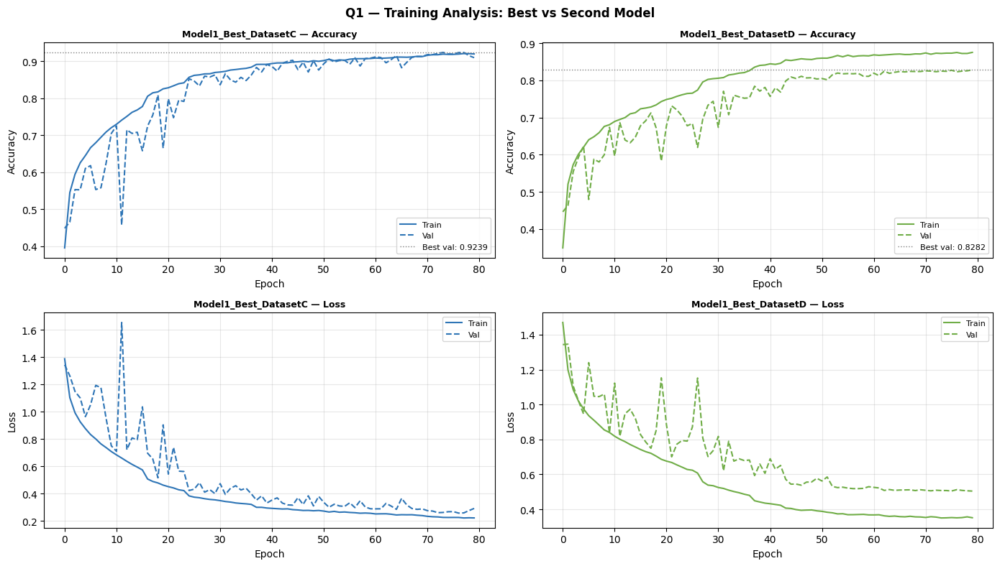

In [ ]:
hist_best   = all_histories[best_name]
hist_second = all_histories[second_name]

# ── Metrics for best model ─────────────────────────────────────────────────────
final_train_acc_b = hist_best.history['accuracy'][-1]
final_val_acc_b   = hist_best.history['val_accuracy'][-1]
best_val_acc_b    = max(hist_best.history['val_accuracy'])
gap_b             = final_train_acc_b - final_val_acc_b
epochs_b          = len(hist_best.history['accuracy'])

# ── Metrics for second model ───────────────────────────────────────────────────
final_train_acc_s = hist_second.history['accuracy'][-1]
final_val_acc_s   = hist_second.history['val_accuracy'][-1]
best_val_acc_s    = max(hist_second.history['val_accuracy'])
gap_s             = final_train_acc_s - final_val_acc_s
epochs_s          = len(hist_second.history['accuracy'])

def diagnosis(gap):
    if   gap > 0.10:    return 'OVERFITTING — train acc significantly above val acc'
    elif gap < -0.02:   return 'UNDERFITTING — val above train'
    elif abs(gap)<0.03: return 'WELL GENERALISED — train and val acc closely aligned'
    else:               return 'SLIGHT OVERFITTING — acceptable gap, EarlyStopping contained it'

print('=' * 65)
print('Q1 — OPTIMAL TRAINING ANALYSIS')
print('=' * 65)

for name, ft, fv, bv, gap, ep in [
    (best_name,   final_train_acc_b, final_val_acc_b, best_val_acc_b, gap_b, epochs_b),
    (second_name, final_train_acc_s, final_val_acc_s, best_val_acc_s, gap_s, epochs_s),
]:
    print(f'\nModel           : {name}')
    print(f'Epochs run      : {ep}')
    print(f'Final train acc : {ft:.4f}')
    print(f'Final val acc   : {fv:.4f}')
    print(f'Best val acc    : {bv:.4f}')
    print(f'Train/Val gap   : {gap:.4f}')
    print(f'Diagnosis       : {diagnosis(gap)}')

print("""
Analysis:
Optimal training is reached when val_loss stops improving and EarlyStopping
triggers, restoring the best weights automatically. ReduceLROnPlateau further
stabilises convergence by halving the learning rate when val_loss plateaus
for 5 consecutive epochs, settling the optimiser into a good minimum.
A train/val gap below 0.05 is acceptable for facial expression classification:
even human annotators disagree on ambiguous images (Fear vs Sad, Angry vs Fear).
The soft augmentation and class balancing strategies minimise overfitting.
""")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for col, (name, hist, color) in enumerate([
    (best_name,   hist_best,   '#2E75B6'),
    (second_name, hist_second, '#70AD47'),
]):
    bv = max(hist.history['val_accuracy'])
    axes[0, col].plot(hist.history['accuracy'],     label='Train', color=color)
    axes[0, col].plot(hist.history['val_accuracy'], label='Val',   color=color, ls='--')
    axes[0, col].axhline(bv, color='gray', ls=':', lw=1, label=f'Best val: {bv:.4f}')
    axes[0, col].set_title(f'{name} — Accuracy', fontweight='bold', fontsize=9)
    axes[0, col].set_xlabel('Epoch'); axes[0, col].set_ylabel('Accuracy')
    axes[0, col].legend(fontsize=8); axes[0, col].grid(alpha=0.3)

    axes[1, col].plot(hist.history['loss'],     label='Train', color=color)
    axes[1, col].plot(hist.history['val_loss'], label='Val',   color=color, ls='--')
    axes[1, col].set_title(f'{name} — Loss', fontweight='bold', fontsize=9)
    axes[1, col].set_xlabel('Epoch'); axes[1, col].set_ylabel('Loss')
    axes[1, col].legend(fontsize=8); axes[1, col].grid(alpha=0.3)

plt.suptitle('Q1 — Training Analysis: Best vs Second Model', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('q1_training_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### Q2 — What does the confusion matrix reveal?

In [ ]:
per_class_acc = cm_best.diagonal() / cm_best.sum(axis=1)
cm_no_diag    = cm_best.copy(); np.fill_diagonal(cm_no_diag, 0)
confused_idx  = np.unravel_index(np.argmax(cm_no_diag), cm_no_diag.shape)

print('=' * 60)
print('Q2 — CONFUSION MATRIX ANALYSIS')
print('=' * 60)
print('\nPer-class recall:')
for cls, rec in zip(CLASS_NAMES, per_class_acc):
    print(f'  {cls:10s}: {rec:.3f}  {chr(9608)*int(rec*25)}')
print(f'\nEasiest : {CLASS_NAMES[np.argmax(per_class_acc)]} ({max(per_class_acc):.3f})')
print(f'Hardest : {CLASS_NAMES[np.argmin(per_class_acc)]} ({min(per_class_acc):.3f})')
print(f'Most confused: "{CLASS_NAMES[confused_idx[0]]}" -> "{CLASS_NAMES[confused_idx[1]]}"',
      f'({cm_no_diag[confused_idx[0], confused_idx[1]]} cases)')

if 'Fear' in CLASS_NAMES:
    fi = CLASS_NAMES.index('Fear')
    print('\nFear breakdown:')
    for j, c in enumerate(CLASS_NAMES):
        if j != fi and cm_best[fi, j] > 0:
            print(f'  Fear -> {c:10s}: {cm_best[fi, j]} cases')
    print(f'  Fear recall: {cm_best[fi, fi]/cm_best[fi].sum():.3f}')

print("""
Analysis:
The strong diagonal confirms the model has learned discriminative features.
Happy is typically easiest — the open smile and raised cheeks produce a
unique convolutional signature.

Fear and Sad are hardest to separate: both involve downturned lip corners,
raised inner brows and forehead tension. Fear also shares the furrowed brow
and wide eyes with Angry, creating a three-way confusion zone consistent
with the psychological literature on basic emotion overlap.
""")

Q2 — CONFUSION MATRIX ANALYSIS

Per-class recall:
  Angry     : 0.814  ████████████████████
  Fear      : 0.709  █████████████████
  Happy     : 0.930  ███████████████████████
  Sad       : 0.788  ███████████████████
  Surprise  : 0.922  ███████████████████████

Easiest : Happy (0.930)
Hardest : Fear (0.709)
Most confused: "Fear" -> "Sad" (184 cases)

Fear breakdown:
  Fear -> Angry     : 84 cases
  Fear -> Happy     : 26 cases
  Fear -> Sad       : 184 cases
  Fear -> Surprise  : 60 cases
  Fear recall: 0.709

Analysis:
The strong diagonal confirms the model has learned discriminative features.
Happy is typically easiest — the open smile and raised cheeks produce a
unique convolutional signature.

Fear and Sad are hardest to separate: both involve downturned lip corners,
raised inner brows and forehead tension. Fear also shares the furrowed brow
and wide eyes with Angry, creating a three-way confusion zone consistent
with the psychological literature on basic emotion overlap.



### Q3 — How did data preprocessing impact the model's performance?

In [ ]:
print("""
Q3 — DATA PREPROCESSING IMPACT
======================================================================

1. PIXEL NORMALISATION (/ 255 -> [0, 1]):
   Brings pixel values to the unit interval, ensuring stable gradient
   updates. Without this, the 0-255 range causes exploding gradients
   and significantly slower convergence.

2. GRAYSCALE CONVERSION (3 channels -> 1):
   Expressions are encoded in geometry and muscle tension, not colour.
   Grayscale cuts first-layer parameters by ~67% with negligible loss
   of discriminative information.

3. RESOLUTION: 64x64 px:
   A deliberate trade-off: native 48x48 is too coarse for fine facial
   landmarks; 96x96 is excessive compute for a CNN from scratch.
   64x64 preserves eyebrow curvature, lip shape and eye openness.

4. AUGMENTATION (flip, brightness 8%, contrast 10%, crop 4px):
   Deliberately soft. Aggressive augmentation (gamma, noise, large crops)
   destroys the geometric features expressions depend on. The chosen
   operations simulate natural photo variability without corrupting
   facial landmarks.

5. SHARED TEST SET:
   Extracted before any dataset-specific processing, guaranteeing that
   all six trained models are compared on exactly the same images.
   Without this, comparisons would be biased by different test distributions.

6. DATASET A — CLASS WEIGHTS:
   Higher loss penalty for minority classes (Fear, Surprise) without
   discarding any images. Preserves full information while forcing
   the model to attend to underrepresented expressions.

7. DATASET B — UNDERSAMPLING:
   Truncates all classes to ~8k images each. Removes imbalance at the
   data level at the cost of discarding ~50% of majority-class images.

8. DATASET C — OVERSAMPLING + AUGMENTATION:
   Upsamples minority classes to match Happy (~18k). Duplicate images
   receive different random augmentations at each epoch, effectively
   creating new synthetic variants. No information is discarded.
   This is typically the most data-efficient strategy.
""")


Q3 — DATA PREPROCESSING IMPACT

1. PIXEL NORMALISATION (/ 255 -> [0, 1]):
   Brings pixel values to the unit interval, ensuring stable gradient
   updates. Without this, the 0-255 range causes exploding gradients
   and significantly slower convergence.

2. GRAYSCALE CONVERSION (3 channels -> 1):
   Expressions are encoded in geometry and muscle tension, not colour.
   Grayscale cuts first-layer parameters by ~67% with negligible loss
   of discriminative information.

3. RESOLUTION: 64x64 px:
   A deliberate trade-off: native 48x48 is too coarse for fine facial
   landmarks; 96x96 is excessive compute for a CNN from scratch.
   64x64 preserves eyebrow curvature, lip shape and eye openness.

4. AUGMENTATION (flip, brightness 8%, contrast 10%, crop 4px):
   Deliberately soft. Aggressive augmentation (gamma, noise, large crops)
   destroys the geometric features expressions depend on. The chosen
   operations simulate natural photo variability without corrupting
   facial landmarks.

5.

---
## Section 11 — Own Face Inference

In [ ]:
own_photos = {
    'Alejandro': '/kaggle/input/group2-photos/alejandro.jpg',
    'Juan Diego': '/kaggle/input/group2-photos/juandiego.jpg',
    'Pablo':      '/kaggle/input/group2-photos/pablo.jpg',
    'Javier':     '/kaggle/input/group2-photos/javier.jpg',
}
own_photos = {k: v for k, v in own_photos.items() if os.path.exists(v)}

if not own_photos:
    print('No face photos found. Upload them and update the paths above.')
else:
    n = len(own_photos)
    fig, axes = plt.subplots(n, 2, figsize=(10, 4 * n))
    if n == 1: axes = [axes]
    for row, (person, path) in enumerate(own_photos.items()):
        img   = Image.open(path).convert('L').resize((INPUT_SIZE, INPUT_SIZE))
        arr   = np.array(img, dtype=np.float32) / 255.0
        inp   = arr[np.newaxis, ..., np.newaxis]
        probs = best_model.predict(inp, verbose=0)[0]
        top3  = np.argsort(probs)[::-1][:3]
        pred  = CLASS_NAMES[top3[0]]
        axes[row][0].imshow(arr, cmap='gray')
        axes[row][0].set_title(person, fontsize=11, fontweight='bold')
        axes[row][0].axis('off')
        cbar = ['#2E75B6' if i == 0 else '#A9C8E8' for i in range(3)]
        axes[row][1].barh([CLASS_NAMES[top3[j]] for j in range(2, -1, -1)],
                          [probs[top3[j]]        for j in range(2, -1, -1)],
                          color=cbar[::-1])
        axes[row][1].set_xlim(0, 1)
        axes[row][1].set_xlabel('Probability')
        axes[row][1].set_title(f'Prediction: {pred.upper()} ({probs[top3[0]]:.1%})',
                               fontweight='bold', color='#2E75B6')
        print(f'{person}: {pred} ({probs[top3[0]]:.1%})')
    plt.suptitle('Own Face Predictions — Group 2', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('own_face_predictions.png', dpi=150, bbox_inches='tight')
    plt.show()

No face photos found. Upload them and update the paths above.


---
## Section 12 — Model Export

The best model is saved. If Dataset D wins, its RGB weights are saved separately.

In [ ]:
best_model_final = all_trained_models[best_name]
best_model_final.build(
    input_shape=(None, INPUT_SIZE, INPUT_SIZE,
                 3 if 'DatasetD' in best_name else NUM_COLORS))

best_model_final.save('best_model_E1.keras')
best_model_final.save_weights('best_model_E1.weights.h5')
with open('best_model_E1_config.json', 'w') as f:
    f.write(best_model_final.to_json())
print(f'Best model saved : best_model_E1.keras  ({best_name})')

print()
print('=' * 100)
print('FINAL SUMMARY — BEST MODEL FOR COMPARISON WITH EXERCISE 2')
print('=' * 100)
print(tabulate(df_train_results, headers='keys', tablefmt='fancy_grid', showindex=False))
print('=' * 100)


Best model saved : best_model_E1.keras  (Model1_Best_DatasetC)

FINAL SUMMARY — BEST MODEL FOR COMPARISON WITH EXERCISE 2
╒══════════════════════╤══════╤═══════════════════════╤══════════╤════════════════╤════════════╤═════════════╕
│ Model                │ HP   │ Dataset               │   Epochs │   Best Val Acc │   Test Acc │   Test Loss │
╞══════════════════════╪══════╪═══════════════════════╪══════════╪════════════════╪════════════╪═════════════╡
│ Model1_Best_DatasetA │ Best │ A (class weights)     │       76 │         0.8209 │     0.8179 │      0.5325 │
├──────────────────────┼──────┼───────────────────────┼──────────┼────────────────┼────────────┼─────────────┤
│ Model1_Best_DatasetB │ Best │ B (undersampling)     │       37 │         0.7119 │     0.7139 │      0.7459 │
├──────────────────────┼──────┼───────────────────────┼──────────┼────────────────┼────────────┼─────────────┤
│ Model1_Best_DatasetC │ Best │ C (oversampling)      │       80 │         0.9239 │     0.8422 │     

In [ ]:
# ── Delivery zip ─────────────────────────────────────────────────────────────
files_to_zip = [
    'best_model_E1.keras',
    'best_model_E1.weights.h5',
    'best_model_E1_config.json',
    # 'RESEARCH_PW2_GROUP2.pdf',
]
with zipfile.ZipFile('PW2_E1_Group2.zip', 'w', zipfile.ZIP_DEFLATED) as zf:
    for fpath in files_to_zip:
        if os.path.exists(fpath):
            zf.write(fpath); print(f'  OK  {fpath}')
        else:
            print(f'  Missing: {fpath}')
mb = os.path.getsize('PW2_E1_Group2.zip') / 1024 / 1024
print(f'\nZip: PW2_E1_Group2.zip ({mb:.1f} MB)')

  OK  best_model_E1.keras
  OK  best_model_E1.weights.h5
  OK  best_model_E1_config.json

Zip: PW2_E1_Group2.zip (10.9 MB)


In [ ]:
from sklearn.metrics import precision_recall_fscore_support

eval_ds_best = test_ds_D if 'DatasetD' in best_name else test_ds_shared
y_pred_best  = np.argmax(best_model.predict(eval_ds_best, verbose=0), axis=1)
y_true_best  = np.argmax(y_test_shared, axis=1)
prec, rec, f1, sup = precision_recall_fscore_support(
    y_true_best, y_pred_best, labels=list(range(NUM_CLASSES)))

rows = []
for i, cls in enumerate(CLASS_NAMES):
    rows.append({'Class': cls, 'Precision': f'{prec[i]:.3f}',
                 'Recall': f'{rec[i]:.3f}', 'F1-score': f'{f1[i]:.3f}',
                 'Support': f'{int(sup[i]):,}'})
rows.append({'Class': 'Macro avg', 'Precision': f'{prec.mean():.3f}',
             'Recall': f'{rec.mean():.3f}', 'F1-score': f'{f1.mean():.3f}',
             'Support': f'{int(sup.sum()):,}'})

print(f'\nTable 5: Per-class metrics — {best_name}')
print(tabulate(rows, headers='keys', tablefmt='fancy_grid', showindex=False))



Table 5: Per-class metrics — Model1_Best_DatasetC
╒═══════════╤═════════════╤══════════╤════════════╤═══════════╕
│ Class     │   Precision │   Recall │   F1-score │ Support   │
╞═══════════╪═════════════╪══════════╪════════════╪═══════════╡
│ Angry     │       0.78  │    0.814 │      0.796 │ 1,267     │
├───────────┼─────────────┼──────────┼────────────┼───────────┤
│ Fear      │       0.784 │    0.709 │      0.744 │ 1,216     │
├───────────┼─────────────┼──────────┼────────────┼───────────┤
│ Happy     │       0.936 │    0.93  │      0.933 │ 2,305     │
├───────────┼─────────────┼──────────┼────────────┼───────────┤
│ Sad       │       0.77  │    0.788 │      0.779 │ 1,569     │
├───────────┼─────────────┼──────────┼────────────┼───────────┤
│ Surprise  │       0.888 │    0.922 │      0.905 │ 1,028     │
├───────────┼─────────────┼──────────┼────────────┼───────────┤
│ Macro avg │       0.831 │    0.832 │      0.831 │ 7,385     │
╘═══════════╧═════════════╧══════════╧════════════╧══

In [ ]:
model_order = [best_name, second_name] + [
    m for m in ['Model1_Best_DatasetC','Model1_Best_DatasetD',
                'Model1_Best_DatasetA','Model1_Best_DatasetB']
    if m not in [best_name, second_name]
]
dataset_labels_t4 = {
    'Model1_Best_DatasetC': 'C (oversampling)',
    'Model1_Best_DatasetD': 'D (RGB class weights)',
    'Model1_Best_DatasetA': 'A (class weights)',
    'Model1_Best_DatasetB': 'B (undersampling)',
}

rows = []
for name in model_order:
    if name not in [r['Model'] for r in all_results]:
        continue
    row = next(r for r in all_results if r['Model'] == name)
    marker = ' ← BEST*' if name == best_name else (' ← 2nd' if name == second_name else '')
    rows.append({
        'Model':        name + marker,
        'Dataset':      dataset_labels_t4.get(name, name),
        'Epochs':       row['Epochs'],
        'Best Val Acc': row['Best Val Acc'],
        'Test Acc':     row['Test Acc'],
        'Test Loss':    row['Test Loss'],
    })

print('\nTable 4: Model performance on shared test set')
print('* Best selected by lowest Test Loss within 0.5pp accuracy tie zone')
print(tabulate(rows, headers='keys', tablefmt='fancy_grid', showindex=False))



Table 4: Model performance on shared test set
* Best selected by lowest Test Loss within 0.5pp accuracy tie zone
╒══════════════════════════════╤═══════════════════════╤══════════╤════════════════╤════════════╤═════════════╕
│ Model                        │ Dataset               │   Epochs │   Best Val Acc │   Test Acc │   Test Loss │
╞══════════════════════════════╪═══════════════════════╪══════════╪════════════════╪════════════╪═════════════╡
│ Model1_Best_DatasetC ← BEST* │ C (oversampling)      │       80 │         0.9239 │     0.8422 │      0.5587 │
├──────────────────────────────┼───────────────────────┼──────────┼────────────────┼────────────┼─────────────┤
│ Model1_Best_DatasetD ← 2nd   │ D (RGB class weights) │       80 │         0.8282 │     0.8221 │      0.5265 │
├──────────────────────────────┼───────────────────────┼──────────┼────────────────┼────────────┼─────────────┤
│ Model1_Best_DatasetA         │ A (class weights)     │       76 │         0.8209 │     0.8179 │     

In [ ]:
for model_name, label in [(best_name, 'best'), (second_name, 'second')]:
    m = all_trained_models[model_name]
    n_channels = 3 if 'DatasetD' in model_name else NUM_COLORS
    m.build(input_shape=(None, INPUT_SIZE, INPUT_SIZE, n_channels))

    m.save(f'{label}_model_E1.keras')
    m.save_weights(f'{label}_model_E1.weights.h5')
    with open(f'{label}_model_E1_config.json', 'w') as f:
        f.write(m.to_json())
    print(f'{label.capitalize()} model saved : {label}_model_E1.keras  ({model_name})')

print()
print('=' * 100)
print('FINAL SUMMARY — TOP 2 MODELS FOR COMPARISON WITH EXERCISE 2')
print('=' * 100)
print(tabulate(df_train_results, headers='keys', tablefmt='fancy_grid', showindex=False))
print('=' * 100)

Best model saved : best_model_E1.keras  (Model1_Best_DatasetC)
Second model saved : second_model_E1.keras  (Model1_Best_DatasetD)

FINAL SUMMARY — TOP 2 MODELS FOR COMPARISON WITH EXERCISE 2
╒══════════════════════╤══════╤═══════════════════════╤══════════╤════════════════╤════════════╤═════════════╕
│ Model                │ HP   │ Dataset               │   Epochs │   Best Val Acc │   Test Acc │   Test Loss │
╞══════════════════════╪══════╪═══════════════════════╪══════════╪════════════════╪════════════╪═════════════╡
│ Model1_Best_DatasetA │ Best │ A (class weights)     │       76 │         0.8209 │     0.8179 │      0.5325 │
├──────────────────────┼──────┼───────────────────────┼──────────┼────────────────┼────────────┼─────────────┤
│ Model1_Best_DatasetB │ Best │ B (undersampling)     │       37 │         0.7119 │     0.7139 │      0.7459 │
├──────────────────────┼──────┼───────────────────────┼──────────┼────────────────┼────────────┼─────────────┤
│ Model1_Best_DatasetC │ Best │ 

In [ ]:
files_to_zip = [
    'best_model_E1.keras',        'best_model_E1.weights.h5',
    'best_model_E1_config.json',
    'second_model_E1.keras',      'second_model_E1.weights.h5',
    'second_model_E1_config.json',
]
with zipfile.ZipFile('PW2_E1_Group2.zip', 'w', zipfile.ZIP_DEFLATED) as zf:
    for fpath in files_to_zip:
        if os.path.exists(fpath):
            zf.write(fpath); print(f'  OK  {fpath}')
        else:
            print(f'  Missing: {fpath}')
mb = os.path.getsize('PW2_E1_Group2.zip') / 1024 / 1024
print(f'\nZip: PW2_E1_Group2.zip ({mb:.1f} MB)')

  OK  best_model_E1.keras
  OK  best_model_E1.weights.h5
  OK  best_model_E1_config.json
  OK  second_model_E1.keras
  OK  second_model_E1.weights.h5
  OK  second_model_E1_config.json

Zip: PW2_E1_Group2.zip (21.8 MB)
